# Улучшение модели оценки стоимости квартир

Эксперименты с трекингом в MLflow: каждая версия модели регистрируется в Model Registry.

- Этап 1. Развёртывание MLflow и регистрация baseline (v1): `run_mlflow_server_full.sh`, `train_old_registry.ipynb`
- Этап 2. EDA и логирование артефактов
- Этап 3. Генерация признаков, модель v2
- Этап 4. Отбор признаков (SFS, SBS), модель v3
- Этап 5. Подбор гиперпараметров (RandomizedSearchCV, Optuna), модель v4

## Этап 2. Исследовательский анализ данных (EDA)

In [ ]:
# настраиваем библиотеки
import os
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import psycopg2

import matplotlib.pyplot as plt
import seaborn as sns


import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature


from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


from sklearn.preprocessing import (
    OneHotEncoder,
    SplineTransformer,
    QuantileTransformer,
    RobustScaler,
    PolynomialFeatures,
    KBinsDiscretizer,
    FunctionTransformer,
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FeatureUnion


from autofeat import AutoFeatRegressor


from catboost import CatBoostRegressor


from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs


import optuna
from optuna import visualization as ov



# путь к старому проекту со спринта 2
OLD_PROJECT_ROOT = Path("/home/mle-user/mle-project-sprint-1-v001/part2_dvc")

DATA_PATH = OLD_PROJECT_ROOT / "data" / "initial_data.csv"
MODEL_PATH = OLD_PROJECT_ROOT / "models" / "fitted_model.pkl"

EXPERIMENT_NAME = "real_estate_price"
RUN_NAME = "baseline_train_valid_test"
REGISTRY_MODEL_NAME = "real_estate_price_model"

mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment(EXPERIMENT_NAME)


<Experiment: artifact_location='s3://<bucket>/1', creation_time=1764534660502, experiment_id='1', last_update_time=1764534660502, lifecycle_stage='active', name='real_estate_price', tags={}>

In [ ]:
# получаем и настраиваем креды
import os
from dotenv import load_dotenv


load_dotenv(dotenv_path="../.env")

True

In [28]:
mlflow_s3_endpoint = os.getenv("MLFLOW_S3_ENDPOINT_URL")
aws_key_id = os.getenv("AWS_ACCESS_KEY_ID")
aws_secret = os.getenv("AWS_SECRET_ACCESS_KEY")

In [29]:
os.environ["MLFLOW_S3_ENDPOINT_URL"] = mlflow_s3_endpoint
os.environ["AWS_ACCESS_KEY_ID"] = aws_key_id
os.environ["AWS_SECRET_ACCESS_KEY"] = aws_secret

In [ ]:
# 2.1 Загрузка данных

In [ ]:
# Имя таблицы с подготовленными признаками
TABLE_NAME = "flats_feature"

ASSETS_DIR = "assets"
os.makedirs(ASSETS_DIR, exist_ok=True)

pd.options.display.max_columns = 100
pd.options.display.max_rows = 64
pd.options.display.float_format ='{:.2f}'.format


sns.set_style("white")
sns.set_theme(style="whitegrid")

# Конфигурация подключения
connection = {
    "sslmode": "require",
    "target_session_attrs": "read-write"
}

postgres_credentials = {
    "host": os.getenv("DB_DESTINATION_HOST"),
    "port": os.getenv("DB_DESTINATION_PORT"),
    "dbname": os.getenv("DB_DESTINATION_NAME"),
    "user": os.getenv("DB_DESTINATION_USER"),
    "password": os.getenv("DB_DESTINATION_PASSWORD")
}

connection.update(postgres_credentials)

# Загрузка данных
with psycopg2.connect(**connection) as conn:
    with conn.cursor() as cur:
        cur.execute(f"SELECT * FROM {TABLE_NAME}")
        data = cur.fetchall()
        columns = [col[0] for col in cur.description]

df = pd.DataFrame(data, columns=columns)

df.head(5)


,id,building_id,build_year,building_type_int,latitude,longitude,ceiling_height,flats_count,floors_total,has_elevator,flat_id,floor,kitchen_area,living_area,rooms,is_apartment,total_area,floors_total_bin,floor_bin,rooms_bin,build_year_bin,price
0,1,6220,None,6,55.717113,37.781120,2.64,84,None,True,0,None,9.9,19.9,None,False,35.099998,low,low,low,med,9500000
1,2,18012,None,2,55.794849,37.608013,3.00,97,None,True,1,None,0.0,16.6,None,False,43.000000,low,low,low,hig,13500000
2,3,17821,None,4,55.740040,37.761742,2.70,80,None,True,2,None,9.0,32.0,None,False,56.000000,low,low,low,hig,13500000
3,4,9293,None,1,55.808807,37.707306,2.60,208,None,True,4,None,3.0,14.0,None,False,24.000000,low,low,low,med,5200000
4,5,23964,None,4,55.724728,37.743069,2.70,192,None,True,5,None,0.0,0.0,None,False,51.009998,low,low,low,hig,8490104


In [21]:
# 2.2. Общий обзор датасета

In [4]:
print("Размер датасета (строки, столбцы):", df.shape)

print("\nПервые 10 строк:")
display(df.head(10))

print("\nИнформация о столбцах:")
df.info()

# Подсчёт пропусков по столбцам
missing_df = (
    df.isna()
    .sum()
    .reset_index()
    .rename(columns={"index": "column", 0: "n_missing"})
)
missing_df["missing_share"] = missing_df["n_missing"] / len(df)

print("\nСтолбцы с наибольшей долей пропусков:")
display(
    missing_df.sort_values("missing_share", ascending=False).head(20)
)

# Разделение на числовые и категориальные признаки
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("\nЧисловые признаки:")
print(numeric_cols)

print("\nКатегориальные признаки:")
print(categorical_cols)

# Базовые статистики по числовым признакам
print("\nОписательные статистики по числовым признакам:")
describe_num = df[numeric_cols].describe().transpose()
display(describe_num)

# Базовые статистики по категориальным признакам
if len(categorical_cols) > 0:
    print("\nОписательные статистики по категориальным признакам:")
    describe_cat = df[categorical_cols].describe().transpose()
    display(describe_cat)


Размер датасета (строки, столбцы): (93487, 22)

Первые 10 строк:


,id,building_id,build_year,building_type_int,latitude,longitude,ceiling_height,flats_count,floors_total,has_elevator,flat_id,floor,kitchen_area,living_area,rooms,is_apartment,total_area,floors_total_bin,floor_bin,rooms_bin,build_year_bin,price
0,1,6220,None,6,55.717113,37.781120,2.64,84,None,True,0,None,9.90,19.900000,None,False,35.099998,low,low,low,med,9500000
1,2,18012,None,2,55.794849,37.608013,3.00,97,None,True,1,None,0.00,16.600000,None,False,43.000000,low,low,low,hig,13500000
2,3,17821,None,4,55.740040,37.761742,2.70,80,None,True,2,None,9.00,32.000000,None,False,56.000000,low,low,low,hig,13500000
3,4,9293,None,1,55.808807,37.707306,2.60,208,None,True,4,None,3.00,14.000000,None,False,24.000000,low,low,low,med,5200000
4,5,23964,None,4,55.724728,37.743069,2.70,192,None,True,5,None,0.00,0.000000,None,False,51.009998,low,low,low,hig,8490104
5,6,23007,None,2,55.656345,37.424335,3.00,512,None,True,7,None,13.50,0.000000,None,False,52.000000,low,low,low,hig,17990000
6,7,13491,None,4,55.574734,37.668686,2.64,127,None,True,8,None,8.18,19.100000,None,False,35.919998,low,low,low,med,6300000
7,8,13731,None,4,55.994698,37.196686,2.64,142,None,True,9,None,8.00,30.000000,None,False,50.000000,low,low,low,med,5900000
8,9,23226,None,4,55.701424,37.930035,2.74,320,None,True,10,None,13.20,33.700001,None,False,60.299999,low,low,low,hig,10400000
9,10,3781,None,1,55.808903,37.653004,2.48,80,None,False,11,None,5.20,28.600000,None,False,43.900002,low,low,low,med,7490000



Информация о столбцах:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93487 entries, 0 to 93486
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 93487 non-null  int64  
 1   building_id        93487 non-null  int64  
 2   build_year         0 non-null      object 
 3   building_type_int  93487 non-null  int64  
 4   latitude           93487 non-null  float64
 5   longitude          93487 non-null  float64
 6   ceiling_height     93487 non-null  float64
 7   flats_count        93487 non-null  int64  
 8   floors_total       0 non-null      object 
 9   has_elevator       93487 non-null  bool   
 10  flat_id            93487 non-null  int64  
 11  floor              0 non-null      object 
 12  kitchen_area       93487 non-null  float64
 13  living_area        93487 non-null  float64
 14  rooms              0 non-null      object 
 15  is_apartment       93487 non-null  bool   
 16

,column,n_missing,missing_share
2,build_year,93487,1.0
8,floors_total,93487,1.0
11,floor,93487,1.0
14,rooms,93487,1.0
1,building_id,0,0.0
0,id,0,0.0
5,longitude,0,0.0
4,latitude,0,0.0
3,building_type_int,0,0.0
7,flats_count,0,0.0



Числовые признаки:
['id', 'building_id', 'building_type_int', 'latitude', 'longitude', 'ceiling_height', 'flats_count', 'flat_id', 'kitchen_area', 'living_area', 'total_area']

Категориальные признаки:
['build_year', 'floors_total', 'has_elevator', 'floor', 'rooms', 'is_apartment', 'floors_total_bin', 'floor_bin', 'rooms_bin', 'build_year_bin', 'price']

Описательные статистики по числовым признакам:


,count,mean,std,min,25%,50%,75%,max
id,93487.0,46744.000000,26987.516645,1.000000,23372.500000,46744.000000,70115.500000,93487.000000
building_id,93487.0,13437.047130,6525.974668,4.000000,8322.000000,13285.000000,18974.000000,24620.000000
building_type_int,93487.0,3.468867,1.423626,0.000000,2.000000,4.000000,4.000000,6.000000
latitude,93487.0,55.730722,0.106581,55.211460,55.650433,55.720310,55.814953,56.011032
longitude,93487.0,37.594737,0.156517,36.864372,37.491871,37.587379,37.716682,37.946411
ceiling_height,93487.0,2.695569,0.137165,2.450000,2.640000,2.640000,2.740000,3.000000
flats_count,93487.0,224.796528,135.130532,1.000000,112.000000,196.000000,306.000000,640.000000
flat_id,93487.0,68539.428733,41194.148178,0.000000,32318.500000,67241.000000,104065.500000,141361.000000
kitchen_area,93487.0,8.147783,3.135767,0.000000,6.000000,8.500000,10.000000,16.300000
living_area,93487.0,27.793535,14.925550,0.000000,19.000000,28.700001,37.000000,74.000000



Описательные статистики по категориальным признакам:


,count,unique,top,freq
build_year,0,0,NaN,NaN
floors_total,0,0,NaN,NaN
has_elevator,93487,2,True,83763
floor,0,0,NaN,NaN
rooms,0,0,NaN,NaN
is_apartment,93487,2,False,92892
floors_total_bin,93487,3,low,80672
floor_bin,93487,3,low,72309
rooms_bin,93487,3,low,91224
build_year_bin,93487,3,med,55447


In [18]:
# 2.3 Анализ признаков для модели

In [5]:
# 2.3.1. Подготовка признаков для анализа

TARGET_COL = "price"

# Приведение price к числовому типу
df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors="coerce")

# Полностью пустые исходные признаки
empty_cols = ["build_year", "floors_total", "floor", "rooms"]

# Удаление пустых столбцов
df = df.drop(columns=empty_cols)

# Технические идентификаторы
id_cols = ["id", "flat_id", "building_id"]

# Неиспользуемые признаки в анализе признаков
not_eda_features = id_cols + [TARGET_COL]

# Числовые признаки, которые реально несут смысл
numeric_cols = [
    col for col in df.select_dtypes(include=["int64", "float64"]).columns
    if col not in not_eda_features
]

# Категориальные признаки
categorical_cols = [
    col for col in df.select_dtypes(include=["object", "category", "bool"]).columns
    if col not in not_eda_features
]

# Бинарные признаки
binary_cols = [
    col for col in categorical_cols
    if df[col].dropna().nunique() == 2
]

# Многокатегориальные признаки
multi_cat_cols = [
    col for col in categorical_cols
    if col not in binary_cols
]

print("Числовые признаки:", numeric_cols)
print("Категориальные признаки:", categorical_cols)
print("Бинарные признаки:", binary_cols)
print("Многокатегориальные признаки:", multi_cat_cols)


Числовые признаки: ['building_type_int', 'latitude', 'longitude', 'ceiling_height', 'flats_count', 'kitchen_area', 'living_area', 'total_area']
Категориальные признаки: ['has_elevator', 'is_apartment', 'floors_total_bin', 'floor_bin', 'rooms_bin', 'build_year_bin']
Бинарные признаки: ['has_elevator', 'is_apartment']
Многокатегориальные признаки: ['floors_total_bin', 'floor_bin', 'rooms_bin', 'build_year_bin']


In [27]:
# 2.3.2. Распределение числовых признаков

fig, axs = plt.subplots(len(numeric_cols), 1, figsize=(10, 4 * len(numeric_cols)))
fig.tight_layout(pad=3)

for ax, col in zip(axs, numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f"Распределение: {col}")
plt.savefig(os.path.join(ASSETS_DIR, 'numeric_features_distribution'))

plt.show()


In [64]:
# 2.3.3.1 Распределение многокатегориальных признаков

fig, axs = plt.subplots(len(multi_cat_cols), 1, figsize=(10, 4 * len(multi_cat_cols)))
fig.tight_layout(pad=3)

for ax, col in zip(axs, multi_cat_cols):
    order = df[col].value_counts().index
    sns.countplot(x=df[col], order=order, ax=ax)
    ax.set_title(f"Распределение категорий: {col}")
    ax.tick_params(axis="x", rotation=45)
plt.savefig(os.path.join(ASSETS_DIR, 'categorical_features_distribution'))

plt.show()



In [65]:
# 2.3.4. Корреляция числовых признаков

plt.figure(figsize=(10, 8))
corr = df[numeric_cols + [TARGET_COL]].corr()
sns.heatmap(corr, annot=False, cmap="coolwarm")
plt.title("Корреляции между числовыми признаками")
plt.savefig(os.path.join(ASSETS_DIR, 'numeric_correlation_heatmap'))

plt.show()



In [66]:
# 2.3.5. Тепловая карта value_counts по бинарным

if len(binary_cols) > 0:
    heat_df = df[binary_cols].apply(pd.Series.value_counts).T
    plt.figure(figsize=(6, 2 + len(binary_cols) * 0.4))
    sns.heatmap(heat_df, annot=True, fmt=".0f")
    plt.title("Частоты значений для бинарных признаков")
    plt.xlabel("value")
    plt.ylabel("feature")
    plt.savefig(os.path.join(ASSETS_DIR, 'binary_features_heatmap'))
    
    plt.show()
    
else:
    print("Бинарных признаков нет.")
    
    


In [ ]:
# 2.4 Анализ целевой переменной

In [35]:
print("Размер выборки:", df[TARGET_COL].shape[0])
print("\nСтатистики price:")
display(df[TARGET_COL].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))


Размер выборки: 93487

Статистики price:


count       93487.00
mean     12404003.40
std       6401463.99
min          1500.00
1%        4999999.00
5%        6300000.00
25%       8500000.00
50%      10900000.00
75%      14300000.00
95%      23700000.00
99%      36000000.00
max     174000000.00
Name: price, dtype: float64

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df[TARGET_COL], kde=True)
plt.title("Распределение цены (price)")
plt.xlabel("price")
plt.ylabel("count")
plt.savefig(os.path.join(ASSETS_DIR, 'target_distribution'))

plt.show()


In [68]:
plt.figure(figsize=(8, 5))
sns.histplot(np.log1p(df[TARGET_COL]), kde=True)
plt.title("Логарифмическое распределение цены (log(price))")
plt.xlabel("log(price)")
plt.ylabel("count")
plt.savefig(os.path.join(ASSETS_DIR, 'log_target_distribution'))

plt.show()



In [40]:
q01 = df[TARGET_COL].quantile(0.01)
q99 = df[TARGET_COL].quantile(0.99)

print("1-й перцентиль:", q01)
print("99-й перцентиль:", q99)

high_outliers = (df[TARGET_COL] > q99).sum()
low_outliers = (df[TARGET_COL] < q01).sum()

print(f"Количество подозрительных низких значений: {low_outliers}")
print(f"Количество подозрительных высоких значений: {high_outliers}")


1-й перцентиль: 4999999.0
99-й перцентиль: 36000000.0
Количество подозрительных низких значений: 934
Количество подозрительных высоких значений: 929


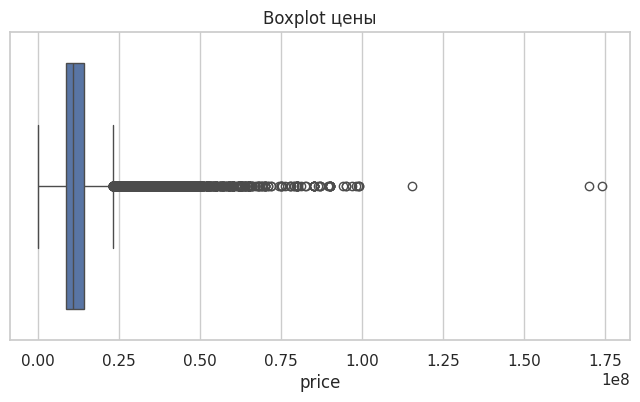

In [69]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df[TARGET_COL])
plt.title("Boxplot цены")
plt.savefig(os.path.join(ASSETS_DIR, 'target_boxplot'))

plt.show()



In [ ]:
# 2.4 Анализ целевой переменной в зависимости от различных признаков

In [70]:
# 2.4.1. Зависимость цены от многокатегориальных признаков

features = multi_cat_cols
n = len(features)

if n > 0:
    rows = int(np.ceil(n / 2))
    cols = 2

    fig, axs = plt.subplots(rows, cols, figsize=(14, 4 * rows))
    axs = axs.flatten()

    for ax, col in zip(axs, features):
        sns.boxplot(data=df, x=col, y=TARGET_COL, ax=ax)
        ax.set_title(f"price vs {col}")
        ax.tick_params(axis='x', rotation=45)

    # если осей больше, чем признаков — отключаем лишние
    for j in range(len(features), len(axs)):
        axs[j].set_visible(False)

    plt.tight_layout()
    plt.savefig(os.path.join(ASSETS_DIR, 'price_vs_categorical_features'))
    
    plt.show()
    
else:
    print("Нет многокатегориальных признаков.")


In [ ]:
# 2.4.2. Зависимость цены от бинарных признаков

features = binary_cols
n = len(features)

if n > 0:
    rows = int(np.ceil(n / 3))
    cols = 3  

    fig, axs = plt.subplots(rows, cols, figsize=(14, 4 * rows))
    axs = axs.flatten()

    for ax, col in zip(axs, features):
        sns.boxplot(data=df, x=col, y=TARGET_COL, ax=ax)
        ax.set_title(f"price vs {col}")

    for j in range(len(features), len(axs)):
        axs[j].set_visible(False)

    plt.tight_layout()
    plt.savefig(os.path.join(ASSETS_DIR, 'price_vs_binary_features'))
    
    plt.show()
    
else:
    print("Нет бинарных признаков.")


In [71]:
# 2.4.3. Зависимость цены от числовых признаков

# выбрасываем признаки, непригодные для scatter (гео отдельно)
num_features = [
    col for col in numeric_cols
    if col not in ["longitude", "latitude"]
]

n = len(num_features)
rows = int(np.ceil(n / 2))
cols = 2

fig, axs = plt.subplots(rows, cols, figsize=(14, 4 * rows))
axs = axs.flatten()

for ax, col in zip(axs, num_features):
    sns.scatterplot(data=df, x=col, y=TARGET_COL, s=10, alpha=0.4, ax=ax)
    sns.regplot(data=df, x=col, y=TARGET_COL, scatter=False, ax=ax, color="red")
    ax.set_title(f"price vs {col}")

for j in range(len(num_features), len(axs)):
    axs[j].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, 'price_vs_numeric_features'))

plt.show()



In [72]:
# 2.4.4. Цена vs география (простая карта)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df.sample(5000, random_state=42),
    x="longitude",
    y="latitude",
    hue=TARGET_COL,
    palette="viridis",
    s=12,
    alpha=0.7
)
plt.title("География объектов с ценой")
plt.savefig(os.path.join(ASSETS_DIR, 'geo_price_scatter'))

plt.show()



In [ ]:
# 2.5 Выводы после EDA

Исследовательский анализ данных показал, что распределения большинства признаков соответствуют типичной структуре городского жилищного фонда. Наиболее выраженная и устойчивая зависимость наблюдается между ценой и площадью объекта. Общая площадь демонстрирует практически монотонный рост стоимости: чем больше площадь, тем выше цена. Жилая площадь и площадь кухни имеют подобную тенденцию, однако там встречается больше колебаний, что объясняется разной планировкой, типами домов и возрастом зданий. Тем не менее, совокупно эти признаки формируют основную объясняющую часть модели и дают стабильный сигнал.

Категориальные признаки также оказывают влияние на стоимость. Количество комнат создаёт заметное разделение между группами: малогабаритные квартиры формируют нижнюю часть ценового диапазона, а трёх- и четырёхкомнатные объекты смещаются к верхней части распределения. Этажность здания и возраст постройки влияют умеренно. Новые дома ожидаемо дороже старых, а высокие дома — дороже малоэтажных. Эти зависимости не такие сильные, как у площадей, но они устойчивы и могут помочь модели корректировать цену в рамках отдельных подгрупп рынка.

Целевая переменная имеет выраженный правый хвост. Большая часть объектов сосредоточена в относительно компактном диапазоне, но встречаются как очень дешёвые, так и аномально дорогие квартиры. Такие значения увеличивают дисперсию и могут ухудшить работу моделей, использующих квадратичную ошибку. Это следует учитывать при выборе функции потерь или при проектировании стратегии обработки выбросов.

Географическое распределение объектов подтверждает пространственную структуру рынка: более дорогие квартиры располагаются ближе к центральной части города, а при удалении стоимость снижается. Это проявляется даже без дополнительных геопризнаков. Наличие отдельных «карманов» с повышенной ценой связано с локальными особенностями районов, что также может быть учтено при дальнейшем моделировании. Предварительные попытки использовать пространственные вычисления и кластеризацию показали, что такие операции создают заметную нагрузку на JupyterHub и могут приводить к перегрузке среды. Поэтому подробный геоанализ на данном этапе был ограничен базовой визуализацией.

В совокупности данные позволяют сделать вывод, что модель будет опираться прежде всего на площадь, количество комнат и некоторые параметры здания. Географические признаки могут дать дополнительный прирост качества, но их использование требует осторожного выбора методов, чтобы не создавать избыточную нагрузку на вычислительную инфраструктуру.

In [ ]:
# 2.6 логирование артефактов в MLflow

In [ ]:
RUN_NAME = "eda_artifacts"


mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment(EXPERIMENT_NAME)

with mlflow.start_run(run_name=RUN_NAME) as run:
    run_id = run.info.run_id

    # Логирование всех файлов из директории с картинками и прочими артефактами
    mlflow.log_artifacts(ASSETS_DIR, artifact_path="eda")

run_id


'021b84da2097483a9fcf48d6b99b1874'

## Этап 3. Генерация признаков и обучение модели (v2)

In [ ]:
# 3.1 ручная генерация признаков

In [28]:
# 3.1 Ручная генерация признаков

MOSCOW_CENTER_LAT = 55.7558
MOSCOW_CENTER_LON = 37.6176

def add_manual_features(df_source: pd.DataFrame) -> pd.DataFrame:
    """Добавляет вручную сконструированные признаки.

    Args:
        df_source (DataFrame): Исходный DataFrame с признаками квартир.

    Returns:
        DataFrame: Копия входного DataFrame с добавленными признаками.
    """
    df_new = df_source.copy()

    # Доли площадей
    # Доля кухни от общей площади
    df_new["kitchen_share"] = (
        df_new["kitchen_area"] / df_new["total_area"]
    ).replace([np.inf, -np.inf], np.nan)

    # Доля жилой площади от общей площади
    df_new["living_share"] = (
        df_new["living_area"] / df_new["total_area"]
    ).replace([np.inf, -np.inf], np.nan)

    # Логарифм общей площади
    df_new["log_total_area"] = np.log1p(df_new["total_area"])

    # Логарифм количества квартир в доме
    df_new["log_flats_count"] = np.log1p(df_new["flats_count"])

    # Приближённое расстояние до центра города по координатам (формула хаверсина)
    lat_rad = np.radians(df_new["latitude"])
    lon_rad = np.radians(df_new["longitude"])
    center_lat_rad = np.radians(MOSCOW_CENTER_LAT)
    center_lon_rad = np.radians(MOSCOW_CENTER_LON)

    dlat = lat_rad - center_lat_rad
    dlon = lon_rad - center_lon_rad

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(center_lat_rad) * np.cos(lat_rad) * np.sin(dlon / 2) ** 2
    )
    c = 2 * np.arcsin(np.sqrt(a))
    earth_radius_km = 6371

    df_new["distance_to_center_km"] = earth_radius_km * c

    return df_new


df_tmp = add_manual_features(df)

manual_feature_cols = [
    "kitchen_share",
    "living_share",
    "log_total_area",
    "log_flats_count",
    "distance_to_center_km",
]

df_tmp[manual_feature_cols].head()


,kitchen_share,living_share,log_total_area,log_flats_count,distance_to_center_km
0,0.282051,0.566952,3.586293,4.442651,11.103941
1,0.000000,0.386047,3.784190,4.584967,4.383294
2,0.160714,0.571429,4.043051,4.394449,9.189657
3,0.125000,0.583333,3.218876,5.342334,8.136619
4,0.000000,0.000000,3.951436,5.262690,8.580310


In [ ]:
# 3.2 оборачивание всех преобразований в объекты sklearn

In [ ]:
def add_manual_features(df_source: pd.DataFrame) -> pd.DataFrame:
    """Добавляет вручную сконструированные признаки.

    Args:
        df_source (DataFrame): Исходный DataFrame с признаками.

    Returns:
        DataFrame: Копия входного DataFrame с добавленными признаками.
    """
    df_new = df_source.copy()

    # Доля кухни от общей площади
    if "kitchen_share" not in df_new.columns:
        df_new["kitchen_share"] = (
            df_new["kitchen_area"] / df_new["total_area"]
        ).replace([np.inf, -np.inf], np.nan)

    # Доля жилой площади от общей площади
    if "living_share" not in df_new.columns:
        df_new["living_share"] = (
            df_new["living_area"] / df_new["total_area"]
        ).replace([np.inf, -np.inf], np.nan)

    # Логи
    if "log_total_area" not in df_new.columns:
        df_new["log_total_area"] = np.log1p(df_new["total_area"])

    if "log_flats_count" not in df_new.columns:
        df_new["log_flats_count"] = np.log1p(df_new["flats_count"])

    # Расстояние до центра (haversine)
    if "distance_to_center_km" not in df_new.columns:
        MOSCOW_CENTER_LAT = 55.7558
        MOSCOW_CENTER_LON = 37.6176

        lat_rad = np.radians(df_new["latitude"])
        lon_rad = np.radians(df_new["longitude"])
        center_lat_rad = np.radians(MOSCOW_CENTER_LAT)
        center_lon_rad = np.radians(MOSCOW_CENTER_LON)

        dlat = lat_rad - center_lat_rad
        dlon = lon_rad - center_lon_rad

        a = (
            np.sin(dlat / 2) ** 2
            + np.cos(center_lat_rad) * np.cos(lat_rad) * np.sin(dlon / 2) ** 2
        )
        c = 2 * np.arcsin(np.sqrt(a))
        earth_radius_km = 6371

        df_new["distance_to_center_km"] = earth_radius_km * c

    return df_new


manual_features_transformer = FunctionTransformer(
    add_manual_features,
    validate=False,
)

# Точечные группы колонок под разные трансформации

# Сплайны по площади и расстоянию до центра
spline_cols = [
    "total_area",
    "distance_to_center_km",
]

# Квантили для признаков с хвостами
quantile_cols = [
    "total_area",
    "living_area",
    "kitchen_area",
]

# Робаст-скейлер для признаков с выбросами
robust_cols = [
    "flats_count",
    "kitchen_area",
    "living_area",
]

# Полиномиальные признаки
poly_cols = [
    "total_area",
    "ceiling_height",
    "distance_to_center_km",
]

# Биннинг по площади и расстоянию
kbins_cols = [
    "total_area",
    "distance_to_center_km",
]

# Сырые числовые признаки, которые просто передаются в модель
raw_num_cols = list({
    "total_area",
    "living_area",
    "kitchen_area",
    "ceiling_height",
    "flats_count",
    "distance_to_center_km",
    "kitchen_share",
    "living_share",
    "log_total_area",
    "log_flats_count",
})

# Эти колонки реально попадут во внешнюю числовую ветку
numeric_input_cols = list(
    dict.fromkeys(
        spline_cols
        + quantile_cols
        + robust_cols
        + poly_cols
        + kbins_cols
        + raw_num_cols
    )
)

# Категориальные и бинарные признаки из EDA + building_type_int как категориальный
cat_columns = multi_cat_cols + binary_cols + ["building_type_int"]
cat_columns = list(dict.fromkeys(cat_columns))


# Параметры трансформаций
encoder_spl = SplineTransformer(
    n_knots=3,
    degree=3,
)

encoder_q = QuantileTransformer(
    n_quantiles=100,
    subsample=None,
)

encoder_rb = RobustScaler()

encoder_pol = PolynomialFeatures(
    degree=2,
    include_bias=False,
)

encoder_kbd = KBinsDiscretizer(
    n_bins=5,
    encode="ordinal",
    strategy="uniform",
)

numeric_branch = ColumnTransformer(
    transformers=[
        ("spl", encoder_spl, spline_cols),
        ("q", encoder_q, quantile_cols),
        ("rb", encoder_rb, robust_cols),
        ("pol", encoder_pol, poly_cols),
        ("kbd", encoder_kbd, kbins_cols),
        ("num_raw", "passthrough", raw_num_cols),
    ],
    remainder="drop",
)

encoder_oh = OneHotEncoder(
    categories="auto",
    handle_unknown="ignore",
    max_categories=10,
    drop="first",
    sparse_output=False,
)

categorical_branch = Pipeline(
    steps=[
        ("encoder", encoder_oh),
    ]
)

preprocessor = Pipeline(
    steps=[
        ("manual_features", manual_features_transformer),
        (
            "column_transformer",
            ColumnTransformer(
                transformers=[
                    ("num", numeric_branch, numeric_input_cols),
                    ("cat", categorical_branch, cat_columns),
                ],
                n_jobs=-1,
            ),
        ),
    ]
)


# Проверка, что не падает
X_sample = df.drop(columns=[TARGET_COL]).iloc[:500]
X_preprocessed_sample = preprocessor.fit_transform(X_sample)
X_preprocessed_sample.shape


(500, 51)

In [7]:
X_preprocessed_sample

array([[0.03973648, 0.54974547, 0.4013784 , ..., 0.        , 0.        ,
        1.        ],
       [0.01671066, 0.45672937, 0.50097621, ..., 0.        , 0.        ,
        0.        ],
       [0.00151417, 0.28822466, 0.62766959, ..., 0.        , 1.        ,
        0.        ],
       ...,
       [0.04865722, 0.57242828, 0.37255759, ..., 0.        , 1.        ,
        0.        ],
       [0.02974101, 0.51741977, 0.43892956, ..., 0.        , 0.        ,
        1.        ],
       [0.02392779, 0.49378436, 0.46426997, ..., 0.        , 1.        ,
        0.        ]])

In [ ]:
# 3.3 автоматическая генерация признаков

In [ ]:
# Категориальные признаки (бинарные + бины + тип дома как категориальный)
cat_features = [
    "floors_total_bin",
    "floor_bin",
    "rooms_bin",
    "build_year_bin",
    "has_elevator",
    "is_apartment",
    "building_type_int",
]

# Числовые признаки для автогенерации
num_features = [
    "total_area",
    "living_area",
    "kitchen_area",
    "ceiling_height",
    "flats_count",
    "latitude",
    "longitude",
]

# Полный список признаков, которые будут поданы в autofeat
autofeat_features = cat_features + num_features

# Набор допустимых трансформаций для autofeat
transformations = ("1/", "log", "abs", "sqrt")

afc = AutoFeatRegressor(
    categorical_cols=cat_features,
    transformations=transformations,
    feateng_steps=1,
    n_jobs=-1,
)

X_sample = df.drop(columns=[TARGET_COL]).iloc[:500]
X_preprocessed_sample = afc.fit_transform(X_sample, df[TARGET_COL].iloc[:500])
X_preprocessed_sample

/home/mle-user/.venv_mlflow/lib/python3.10/site-packages/autofeat/featsel.py:270: FutureWarning: Series.ravel is deprecated. The underlying array is already 1D, so ravel is not necessary.  Use `to_numpy()` for conversion to a numpy array instead.
  if np.max(np.abs(correlations[c].ravel()[:i])) < 0.9:


,id,building_id,latitude,longitude,ceiling_height,flats_count,flat_id,kitchen_area,living_area,total_area,cat_floors_total_bin_hig,cat_floors_total_bin_low,cat_floors_total_bin_med,cat_floor_bin_hig,cat_floor_bin_low,cat_floor_bin_med,cat_rooms_bin_low,cat_rooms_bin_med,cat_build_year_bin_hig,cat_build_year_bin_low,cat_build_year_bin_med,cat_has_elevator_False,cat_has_elevator_True,cat_is_apartment_False,cat_is_apartment_True,cat_building_type_int_0,cat_building_type_int_1,cat_building_type_int_2,cat_building_type_int_3,cat_building_type_int_4,cat_building_type_int_6
0,1,6220,55.717113,37.78112,2.64,84,0,9.9,19.9,35.099998,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2,18012,55.794849,37.608013,3.0,97,1,0.0,16.6,43.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,3,17821,55.74004,37.761742,2.7,80,2,9.0,32.0,56.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,4,9293,55.808807,37.707306,2.6,208,4,3.0,14.0,24.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,5,23964,55.724728,37.743069,2.7,192,5,0.0,0.0,51.009998,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,4723,55.515182,37.566746,2.5,48,689,6.0,30.0,44.299999,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
496,497,13470,55.827442,37.577175,2.48,111,690,11.0,29.0,52.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
497,498,7899,55.866722,37.50061,2.64,140,691,7.0,19.6,32.900002,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
498,499,6288,55.844227,37.563538,2.64,72,693,7.5,24.0,38.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [ ]:
# 3.4 обучение новой версии модели

In [ ]:
# если падает, то надо запустить просто ещё раз ячейку, непобедимый баг afc  именно на этом этапе, на следующих лечится

# Разделение данных на train / valid / test (60 / 20 / 20)
X_full = df.drop(columns=[TARGET_COL])
y_full = df[TARGET_COL]

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_full,
    y_full,
    test_size=0.2,
    random_state=42,
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,  # 0.25 от 0.8 = 0.2 от всего датасета
    random_state=42,
)

# Трансформер, который выбирает только колонки для autofeat
autofeat_selector = FunctionTransformer(
    lambda data: data[autofeat_features],
    validate=False,
)
autofeat_pipeline = Pipeline(
    steps=[
        ("select", autofeat_selector),
        ("afc", afc),
    ]
)

# Объединение двух веток признаков:
#  - preprocessor: ручные + sklearn-преобразования
#  - autofeat_pipeline: автоматическая генерация признаков
features_union = FeatureUnion(
    transformer_list=[
        ("preprocessed", preprocessor),
        ("autofeat", autofeat_pipeline),
    ]
)

# Параметры для новой версии модели (пример, аналог старой логики)
model_params = {
    "iterations": 500,
    "learning_rate": 0.05,
    "depth": 6,
}

model = CatBoostRegressor(
    iterations=model_params["iterations"],
    learning_rate=model_params["learning_rate"],
    depth=model_params["depth"],
    loss_function="RMSE",
    verbose=0,
)

# Финальный пайплайн
pipeline = Pipeline(
    steps=[
        ("features", features_union),
        ("model", model),
    ]
)

# Обучение модели
pipeline.fit(X_train, y_train)

# Предсказания
y_pred_valid = pipeline.predict(X_valid)
y_pred_test = pipeline.predict(X_test)

# Подсчёт метрик
metrics = {}

# VALID
mse_valid = mean_squared_error(y_valid, y_pred_valid)
metrics["rmse_valid"] = np.sqrt(mse_valid)
metrics["mae_valid"] = mean_absolute_error(y_valid, y_pred_valid)
metrics["r2_valid"] = r2_score(y_valid, y_pred_valid)

# TEST

mse_test = mean_squared_error(y_test, y_pred_test)
metrics["rmse_test"] = np.sqrt(mse_test)
metrics["mae_test"] = mean_absolute_error(y_test, y_pred_test)
metrics["r2_test"] = r2_score(y_test, y_pred_test)

metrics


/home/mle-user/.venv_mlflow/lib/python3.10/site-packages/autofeat/featsel.py:270: FutureWarning: Series.ravel is deprecated. The underlying array is already 1D, so ravel is not necessary.  Use `to_numpy()` for conversion to a numpy array instead.
  if np.max(np.abs(correlations[c].ravel()[:i])) < 0.9:
/home/mle-user/.venv_mlflow/lib/python3.10/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/mle-user/.venv_mlflow/lib/python3.10/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


{'rmse_valid': 3295999.472639929,
 'mae_valid': 2184766.1074799253,
 'r2_valid': 0.7352156091470031,
 'rmse_test': 3316385.497593774,
 'mae_test': 2182758.845519022,
 'r2_test': 0.7368799487043078}

In [ ]:
# 3.5 логирование артефактов в MLflow

In [ ]:
EXPERIMENT_NAME = "real_estate_price"
RUN_NAME = "step3_model_with_features_autofeat"
REGISTRY_MODEL_NAME = "real_estate_price_model_v2"

mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment(EXPERIMENT_NAME)

# Подпись и пример входа для инференса:
# используем сырые X_test (до препроцессинга), предсказания pipeline
signature = infer_signature(X_test, y_pred_test)
input_example = X_test.iloc[:5]

metadata = {
    "stage": "features_v2",
    "split_scheme": "train/valid/test = 60/20/20",
    "source_project": "mle-project-sprint-2", 
    "model_type": type(pipeline.named_steps["model"]).__name__,
}

with mlflow.start_run(run_name=RUN_NAME) as run:
    run_id = run.info.run_id

    # Метрики
    mlflow.log_metrics(metrics)

    # Параметры модели (CatBoostRegressor в пайплайне)
    if hasattr(pipeline.named_steps["model"], "get_params"):
        mlflow.log_params(pipeline.named_steps["model"].get_params())

    # Логирование препроцессора отдельно
    mlflow.sklearn.log_model(
        sk_model=preprocessor,
        artifact_path="preprocessor",
    )

    # Логирование autofeat-объекта отдельно
    mlflow.sklearn.log_model(
        sk_model=afc,
        artifact_path="afc",
    )

    # Логирование полной модели (features_union + CatBoost)
    model_info = mlflow.sklearn.log_model(
        sk_model=pipeline,
        artifact_path="model",
        registered_model_name=REGISTRY_MODEL_NAME,
        signature=signature,
        input_example=input_example,
        pip_requirements="../requirements.txt",
        metadata=metadata,
        await_registration_for=60,
    )

run_id, model_info.model_uri


/home/mle-user/.venv_mlflow/lib/python3.10/site-packages/mlflow/models/signature.py:212: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  inputs = _infer_schema(model_input) if model_input is not None else None
2025/12/02 19:29:02 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
Successfully registered model 'real_estate_price_mo

('376b1228350d459bb2d99279c87de206',
 'runs:/376b1228350d459bb2d99279c87de206/model')

## Этап 4. Отбор признаков и обучение модели (v3)

In [ ]:
# 4.1 Отбор признаков при помощи метода номер 1



In [ ]:
# 1. Фитим preprocessor отдельно для оптимизации
preprocessor.fit(X_train)
X_preproc = preprocessor.transform(X_train)

col_trans = preprocessor.named_steps["column_transformer"]
preproc_feature_names = col_trans.get_feature_names_out()

# 2. Фитим autofeat отдельно
X_autofeat_train = X_train[autofeat_features]
X_autofeat_transformed = afc.fit_transform(X_autofeat_train, y_train)
autofeat_feature_names = list(X_autofeat_transformed.columns)

# 3. Объединяем фичи вручную, как делает FeatureUnion
X_train_features = np.hstack([X_preproc, X_autofeat_transformed])

feature_names = list(preproc_feature_names) + list(autofeat_feature_names)

X_train_features_df = pd.DataFrame(
    X_train_features,
    columns=feature_names,
    index=X_train.index,
)

print("Форма X_train_features_df:", X_train_features_df.shape)
X_train_features_df

/home/mle-user/.venv_mlflow/lib/python3.10/site-packages/autofeat/featsel.py:270: FutureWarning: Series.ravel is deprecated. The underlying array is already 1D, so ravel is not necessary.  Use `to_numpy()` for conversion to a numpy array instead.
  if np.max(np.abs(correlations[c].ravel()[:i])) < 0.9:


Форма X_train_features_df: (56091, 81)


,num__spl__total_area_sp_0,num__spl__total_area_sp_1,num__spl__total_area_sp_2,num__spl__total_area_sp_3,num__spl__total_area_sp_4,num__spl__distance_to_center_km_sp_0,num__spl__distance_to_center_km_sp_1,num__spl__distance_to_center_km_sp_2,num__spl__distance_to_center_km_sp_3,num__spl__distance_to_center_km_sp_4,num__q__total_area,num__q__living_area,num__q__kitchen_area,num__rb__flats_count,num__rb__kitchen_area,num__rb__living_area,num__pol__total_area,num__pol__ceiling_height,num__pol__distance_to_center_km,num__pol__total_area^2,num__pol__total_area ceiling_height,num__pol__total_area distance_to_center_km,num__pol__ceiling_height^2,num__pol__ceiling_height distance_to_center_km,num__pol__distance_to_center_km^2,num__kbd__total_area,num__kbd__distance_to_center_km,num__num_raw__kitchen_area,num__num_raw__kitchen_share,num__num_raw__ceiling_height,num__num_raw__living_area,num__num_raw__distance_to_center_km,num__num_raw__log_total_area,num__num_raw__living_share,num__num_raw__flats_count,num__num_raw__total_area,num__num_raw__log_flats_count,cat__floors_total_bin_low,cat__floors_total_bin_med,cat__floor_bin_low,cat__floor_bin_med,cat__rooms_bin_low,cat__rooms_bin_med,cat__build_year_bin_low,cat__build_year_bin_med,cat__has_elevator_True,cat__is_apartment_True,cat__building_type_int_1,cat__building_type_int_2,cat__building_type_int_3,cat__building_type_int_4,cat__building_type_int_6,total_area,living_area,kitchen_area,ceiling_height,flats_count,latitude,longitude,cat_floors_total_bin_hig,cat_floors_total_bin_low,cat_floors_total_bin_med,cat_floor_bin_hig,cat_floor_bin_low,cat_floor_bin_med,cat_rooms_bin_hig,cat_rooms_bin_low,cat_rooms_bin_med,cat_build_year_bin_hig,cat_build_year_bin_low,cat_build_year_bin_med,cat_has_elevator_False,cat_has_elevator_True,cat_is_apartment_False,cat_is_apartment_True,cat_building_type_int_0,cat_building_type_int_1,cat_building_type_int_2,cat_building_type_int_3,cat_building_type_int_4,cat_building_type_int_6
38102,0.0,0.081811,0.626785,0.289835,0.001569,0.019659,0.473161,0.485126,0.022053,0.0,0.890011,0.858586,0.936869,0.645833,1.075,0.888889,76.099998,2.74,18.220228,5791.209768,208.513997,1386.559302,7.5076,49.923424,331.976698,3.0,1.0,12.8,0.1682,2.74,44.699997,18.220228,4.345103,0.587385,320.0,76.099998,5.771441,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,76.099998,44.699997,12.8,2.74,320,55.591953,37.614124,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
11238,0.0,0.002096,0.303699,0.618872,0.075333,0.114495,0.653642,0.231592,0.000271,0.0,0.991778,0.969697,0.989899,-0.09375,1.625,1.516667,106.0,3.0,4.70035,11236.0,318.0,498.237096,9.0,14.10105,22.09329,4.0,0.0,15.0,0.141509,3.0,56.0,4.70035,4.672829,0.528302,178.0,106.0,5.187386,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,106.0,56.0,15.0,3.0,178,55.720688,37.659409,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
59,0.000345,0.237473,0.65146,0.110721,0.0,0.038558,0.546364,0.405485,0.009594,0.0,0.664983,0.805556,0.287879,0.473958,-0.5,0.738889,57.900002,2.5,13.961523,3352.410177,144.750004,808.372192,6.25,34.903807,194.924119,2.0,0.0,6.5,0.112263,2.5,42.0,13.961523,4.075841,0.725389,287.0,57.900002,5.66296,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,57.900002,42.0,6.5,2.5,287,55.703709,37.820484,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
12154,0.00267,0.316478,0.611126,0.069725,0.0,0.020469,0.477333,0.480996,0.021202,0.0,0.528139,0.526936,0.459596,1.932292,-0.1,0.038889,51.200001,2.64,17.991104,2621.440078,135.168007,921.144524,6.969601,47.496516,323.679813,1.0,1.0,8.1,0.158203,2.64,29.4,17.991104,3.955083,0.574219,567.0,51.200001,6.342121,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,51.200001,29.4,8.1,2.64,567,55.610119,37.742466,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
47259,0.013316,0.434818,0.521113,0.03

In [11]:
# после fit на train
col_trans = preprocessor.named_steps["column_transformer"]
preproc_feature_names = col_trans.get_feature_names_out()
autofeat_feature_names = list(X_autofeat_transformed.columns)
feature_names = list(preproc_feature_names) + list(autofeat_feature_names)


<!-- здесь я предварительно убираю часть признаков по RandomForest, потому что ВМ Яндекса не отрабатывает столько, сколько нужно SFS. Она падает по времени и всё заново надо -->

In [ ]:
FS_ASSETS = "FS_ASSETS"
os.makedirs(FS_ASSETS, exist_ok=True)

print("Форма X_train_features_df:", X_train_features_df.shape)

# Семплирование строк для отбора признаков
max_samples = 10000
if len(X_train_features_df) > max_samples:
    X_fs, _, y_fs, _ = train_test_split(
        X_train_features_df,
        y_train,
        train_size=max_samples,
        random_state=42,
        shuffle=True,
    )
else:
    X_fs = X_train_features_df
    y_fs = y_train

print("Число строк для отбора признаков:", len(X_fs))

# Быстрый скрининг признаков случайным лесом
rf_screen = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1,
)

rf_screen.fit(X_fs, y_fs)

importances = rf_screen.feature_importances_
feature_importances = pd.Series(importances, index=X_fs.columns)

top_n = min(30, X_fs.shape[1])
top_features_screened = (
    feature_importances.sort_values(ascending=False)
    .head(top_n)
    .index.tolist()
)

print("Число признаков после скрининга:", len(top_features_screened))
top_features_screened
X_sfs = X_fs[top_features_screened]

# Модель для SFS
rf_sfs = RandomForestRegressor(
    n_estimators=80,
    max_depth=None,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1,
)

k_features = 10

sfs = SFS(
    estimator=rf_sfs,
    k_features=k_features,
    forward=True,
    floating=False,
    scoring="neg_mean_squared_error",
    cv=3,
    n_jobs=-1,
    verbose=2,
)

sfs = sfs.fit(X_sfs.values, y_fs)

sfs_idx = list(sfs.k_feature_idx_)
top_sfs = [top_features_screened[i] for i in sfs_idx]

print("SFS: выбранные признаки:")
for f in top_sfs:
    print(f"  {f}")
print("SFS: лучшая CV-оценка (neg_MSE):", sfs.k_score_)

# Сохранение результатов SFS в CSV
sfs_df = pd.DataFrame.from_dict(sfs.get_metric_dict()).T
sfs_csv_path = os.path.join(FS_ASSETS, "sfs.csv")
sfs_df.to_csv(sfs_csv_path, index=False)

# Сохранение графика SFS
fig = plot_sfs(sfs.get_metric_dict(), kind="std_dev")
plt.title("Sequential Forward Selection (RandomForestRegressor)")
plt.grid()
plt.tight_layout()
sfs_png_path = os.path.join(FS_ASSETS, "sfs.png")
plt.savefig(sfs_png_path)
plt.close()


Форма X_train_features_df: (56091, 82)


Число строк для отбора признаков: 10000
Число признаков после скрининга: 30


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:   50.2s finished

[2025-12-02 21:29:39] Features: 1/10 -- score: -20570226331219.438[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  29 out of  29 | elapsed:   53.2s finished

[2025-12-02 21:30:32] Features: 2/10 -- score: -14282536046437.22[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  28 out of  28 | elapsed:  1.5min finished

[2025-12-02 21:32:02] Features: 3/10 -- score: -12924919297312.766[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  27 out of  27 | elapsed:  1.8min finished

[2025-12-02 21:33:49] Features: 4/10 -- score: -12554303808436.352[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 out of  26 | elapsed:  1.8min finishe

SFS: выбранные признаки:
  num__pol__total_area ceiling_height
  longitude
  num__spl__distance_to_center_km_sp_3
  num__pol__distance_to_center_km^2
  num__spl__distance_to_center_km_sp_0
  latitude
  cat__building_type_int_2
  cat_building_type_int_2
  cat_build_year_bin_hig
  num__q__kitchen_area
SFS: лучшая CV-оценка (neg_MSE): -12174621528691.873


In [ ]:
# 4.2 Отбор признаков при помощи метода номер 2

In [ ]:
print("Форма X_train_features_df:", X_train_features_df.shape)

# Семплирование строк для отбора признаков (уменьшаем выборку)
max_samples = 5000
if len(X_train_features_df) > max_samples:
    X_fs_2, _, y_fs_2, _ = train_test_split(
        X_train_features_df,
        y_train,
        train_size=max_samples,
        random_state=42,
        shuffle=True,
    )
else:
    X_fs_2 = X_train_features_df
    y_fs_2 = y_train

print("Число строк для отбора признаков (метод 2):", len(X_fs_2))


rf_screen_2 = RandomForestRegressor(
    n_estimators=50,
    max_depth=None,
    min_samples_leaf=15,
    random_state=42,
    n_jobs=-1,
)

rf_screen_2.fit(X_fs_2, y_fs_2)

importances_2 = rf_screen_2.feature_importances_
feature_importances_2 = pd.Series(importances_2, index=X_fs_2.columns)

top_n_2 = min(15, X_fs_2.shape[1])
top_features_screened_2 = (
    feature_importances_2.sort_values(ascending=False)
    .head(top_n_2)
    .index.tolist()
)

print("Число признаков после скрининга (метод 2):", len(top_features_screened_2))

X_sbs = X_fs_2[top_features_screened_2]


rf_sbs = RandomForestRegressor(
    n_estimators=60,
    max_depth=None,
    min_samples_leaf=25,
    random_state=42,
    n_jobs=-1,
)

k_features_2 = 6

sbs = SFS(
    estimator=rf_sbs,
    k_features=k_features_2,
    forward=False,              # backward selection
    floating=False,
    scoring="neg_mean_squared_error",
    cv=2,                       
    n_jobs=-1,
    verbose=1,                  
)

# приводим к float32, чтобы чуть ускорить вычисления
X_sbs_values = X_sbs.values.astype("float32")

sbs = sbs.fit(X_sbs_values, y_fs_2)

sbs_idx = list(sbs.k_feature_idx_)
top_sbs = [top_features_screened_2[i] for i in sbs_idx]

print("SBS: выбранные признаки:")
for f in top_sbs:
    print(f"  {f}")
print("SBS: лучшая CV-оценка (neg_MSE):", sbs.k_score_)

# Сохранение результатов SBS в CSV
sbs_df = pd.DataFrame.from_dict(sbs.get_metric_dict()).T
sbs_csv_path = os.path.join(FS_ASSETS, "sbs.csv")
sbs_df.to_csv(sbs_csv_path, index=False)

# Сохранение графика SBS
fig = plot_sfs(sbs.get_metric_dict(), kind="std_dev")
plt.title("Sequential Backward Selection (RandomForestRegressor)")
plt.grid()
plt.tight_layout()
sbs_png_path = os.path.join(FS_ASSETS, "sbs.png")
plt.savefig(sbs_png_path)
plt.show()


Форма X_train_features_df: (56091, 82)
Число строк для отбора признаков (метод 2): 5000
Число признаков после скрининга (метод 2): 15


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  15 out of  15 | elapsed:   36.4s finished
Features: 14/6[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  14 out of  14 | elapsed:   24.2s finished
Features: 13/6[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  13 out of  13 | elapsed:   22.9s finished
Features: 12/6[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  12 out of  12 | elapsed:   22.2s finished
Features: 11/6[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  11 out of  11 | elapsed:   15.3s finished
Features: 10/6[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed:   15.3s finished
Features: 9/6[Parallel(n_jobs=-1)]: Using backen

SBS: выбранные признаки:
  num__pol__total_area ceiling_height
  longitude
  num__pol__ceiling_height distance_to_center_km
  num__num_raw__distance_to_center_km
  latitude
  num__num_raw__living_share
SBS: лучшая CV-оценка (neg_MSE): -14923311321844.21


In [ ]:
# 4.3 Анализ отобранных признаков при помощи двух методов и формирование финального списка с признаками для модели

In [25]:
# 4.3 Анализ отобранных признаков при помощи двух методов
#     и формирование финального списка с признаками для модели

set_sfs = set(top_sfs)
set_sbs = set(top_sbs)

interc_features = sorted(set_sfs & set_sbs)
only_sfs = sorted(set_sfs - set_sbs)
only_sbs = sorted(set_sbs - set_sfs)
union_features = sorted(set_sfs | set_sbs)

print(f"Метод 1 (SFS): {len(top_sfs)} признаков")
print(f"Метод 2 (SBS): {len(top_sbs)} признаков")
print(f"Общие признаки (пересечение): {len(interc_features)}")
print("Общие признаки:")
for f in interc_features:
    print(" ", f)

print("\nТолько метод 1 (SFS):")
for f in only_sfs:
    print(" ", f)

print("\nТолько метод 2 (SBS):")
for f in only_sbs:
    print(" ", f)

print("\nОбъединение признаков (union):", len(union_features))
for f in union_features:
    print(" ", f)


Метод 1 (SFS): 10 признаков
Метод 2 (SBS): 6 признаков
Общие признаки (пересечение): 3
Общие признаки:
  latitude
  longitude
  num__pol__total_area ceiling_height

Только метод 1 (SFS):
  cat__building_type_int_2
  cat_build_year_bin_hig
  cat_building_type_int_2
  num__pol__distance_to_center_km^2
  num__q__kitchen_area
  num__spl__distance_to_center_km_sp_0
  num__spl__distance_to_center_km_sp_3

Только метод 2 (SBS):
  num__num_raw__distance_to_center_km
  num__num_raw__living_share
  num__pol__ceiling_height distance_to_center_km

Объединение признаков (union): 13
  cat__building_type_int_2
  cat_build_year_bin_hig
  cat_building_type_int_2
  latitude
  longitude
  num__num_raw__distance_to_center_km
  num__num_raw__living_share
  num__pol__ceiling_height distance_to_center_km
  num__pol__distance_to_center_km^2
  num__pol__total_area ceiling_height
  num__q__kitchen_area
  num__spl__distance_to_center_km_sp_0
  num__spl__distance_to_center_km_sp_3


In [ ]:
# 4.4 Обучение новой версии модели

In [ ]:
# сохраняем признаки, чтобы не перезапускать отбор признаков при перезапуске ВМ яндекса
union_features = [
    'cat__building_type_int_2', 
    'cat_build_year_bin_hig', 
    'cat_building_type_int_2', 
    'latitude', 
    'longitude', 
    'num__num_raw__distance_to_center_km', 
    'num__num_raw__living_share', 
    'num__pol__ceiling_height distance_to_center_km', 
    'num__pol__distance_to_center_km^2', 
    'num__pol__total_area ceiling_height', 
    'num__q__kitchen_area', 
    'num__spl__distance_to_center_km_sp_0', 
    'num__spl__distance_to_center_km_sp_3', 
    ]

In [ ]:
# 4.4.1 Строим матрицы признаков для train/valid/test с учётом union_features

def build_features_df(X, preprocessor, afc, autofeat_features,
                      preproc_feature_names, autofeat_feature_names):
    X_preproc = preprocessor.transform(X)
    X_autofeat = afc.transform(X[autofeat_features])

    # выравниваем столбцы autofeat под train
    X_autofeat = X_autofeat.reindex(
        columns=autofeat_feature_names,
        fill_value=0.0,
    )

    X_features = np.hstack([X_preproc, X_autofeat])

    feature_names_all = list(preproc_feature_names) + list(autofeat_feature_names)

    assert X_features.shape[1] == len(feature_names_all)

    df_features = pd.DataFrame(
        X_features,
        columns=feature_names_all,
        index=X.index,
    )
    return df_features


X_train_feat_full = X_train_features_df  
X_valid_feat_full = build_features_df(
    X_valid,
    preprocessor=preprocessor,
    afc=afc,
    autofeat_features=autofeat_features,
    preproc_feature_names=preproc_feature_names,
    autofeat_feature_names=autofeat_feature_names,
)

X_test_feat_full = build_features_df(
    X_test,
    preprocessor=preprocessor,
    afc=afc,
    autofeat_features=autofeat_features,
    preproc_feature_names=preproc_feature_names,
    autofeat_feature_names=autofeat_feature_names,
)


# Оставляем только признаки из объединения двух методов
X_train_fs = X_train_feat_full[union_features]
X_valid_fs = X_valid_feat_full[union_features]
X_test_fs = X_test_feat_full[union_features]

print("Формы после отбора признаков:")
print("X_train_fs:", X_train_fs.shape)
print("X_valid_fs:", X_valid_fs.shape)
print("X_test_fs:", X_test_fs.shape)

# 4.4.2 Обучение новой версии модели

model_fs = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="RMSE",
    verbose=0,
)

model_fs.fit(X_train_fs, y_train)

y_pred_valid_fs = model_fs.predict(X_valid_fs)
y_pred_test_fs = model_fs.predict(X_test_fs)

metrics_fs = {}

# VALID
mse_valid_fs = mean_squared_error(y_valid, y_pred_valid_fs)
metrics_fs["rmse_valid"] = np.sqrt(mse_valid_fs)
metrics_fs["mae_valid"] = mean_absolute_error(y_valid, y_pred_valid_fs)
metrics_fs["r2_valid"] = r2_score(y_valid, y_pred_valid_fs)

# TEST
mse_test_fs = mean_squared_error(y_test, y_pred_test_fs)
metrics_fs["rmse_test"] = np.sqrt(mse_test_fs)
metrics_fs["mae_test"] = mean_absolute_error(y_test, y_pred_test_fs)
metrics_fs["r2_test"] = r2_score(y_test, y_pred_test_fs)

metrics_fs


/home/mle-user/.venv_mlflow/lib/python3.10/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/mle-user/.venv_mlflow/lib/python3.10/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Формы после отбора признаков:
X_train_fs: (56091, 13)
X_valid_fs: (18698, 13)
X_test_fs: (18698, 13)


{'rmse_valid': 3097209.776937033,
 'mae_valid': 2113220.966541618,
 'r2_valid': 0.7661920060734889,
 'rmse_test': 3142009.239152985,
 'mae_test': 2123621.464172458,
 'r2_test': 0.7638223233492101}

In [ ]:
# 4.5 Логирование всех артефактов в MLflow

In [ ]:
EXPERIMENT_NAME = "real_estate_price"
RUN_NAME = "step4_model_with_feature_selection_union"
REGISTRY_MODEL_NAME = "real_estate_price_model_v3_fs"

mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment(EXPERIMENT_NAME)

signature_fs = infer_signature(X_test_fs, y_pred_test_fs)
input_example_fs = X_test_fs.iloc[:5]

metadata_fs = {
    "stage": "features_v2_fs_union",
    "split_scheme": "train/valid/test = 60/20/20",
    "source_project": "mle-project-sprint-2",
    "model_type": type(model_fs).__name__,
    "feature_selection": "SFS+SBS_union",
}

with mlflow.start_run(run_name=RUN_NAME) as run:
    run_id = run.info.run_id

    # метрики
    mlflow.log_metrics(metrics_fs)

    # параметры модели
    if hasattr(model_fs, "get_params"):
        mlflow.log_params(model_fs.get_params())

    # логируем артефакты отбора признаков
    mlflow.log_artifacts(FS_ASSETS)

    # логируем финальный список признаков
    final_list_path = os.path.join(FS_ASSETS, "final_features_union.txt")
    with open(final_list_path, "w", encoding="utf-8") as f:
        for col in union_features:
            f.write(col + "\n")
    mlflow.log_artifact(final_list_path, artifact_path="feature_selection")

    # логируем модель на отобранных признаках
    model_info_fs = mlflow.sklearn.log_model(
        sk_model=model_fs,
        artifact_path="model_fs_union",
        registered_model_name=REGISTRY_MODEL_NAME,
        signature=signature_fs,
        input_example=input_example_fs,
        pip_requirements="../requirements.txt",
        metadata=metadata_fs,
        await_registration_for=60,
    )

run_id, model_info_fs.model_uri


2025-12-02 22:09:26,246 INFO: Found credentials in environment variables.
Successfully registered model 'real_estate_price_model_v3_fs'.
2025/12/02 22:09:29 INFO mlflow.tracking._model_registry.client: Waiting up to 60 seconds for model version to finish creation. Model name: real_estate_price_model_v3_fs, version 1
Created version '1' of model 'real_estate_price_model_v3_fs'.


('c4e5886ead684fefa4f617fbeb683492',
 'runs:/c4e5886ead684fefa4f617fbeb683492/model_fs_union')

## Этап 5. Подбор гиперпараметров и финальная модель (v4)

In [ ]:
# 5.1 Подбор гиперпарметров при мощи метода номер 1

In [ ]:
cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42,
)

base_model = CatBoostRegressor(
    loss_function="RMSE",
    iterations=500,
    random_seed=42,
    verbose=0,
)

param_distributions = {
    "depth": [4, 6, 8],
    "learning_rate": np.linspace(0.02, 0.1, 5),
    "l2_leaf_reg": np.logspace(0, 2, 5),
    "bagging_temperature": [0, 1, 5],
}

random_search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    verbose=2,
    random_state=42,
)

random_search.fit(X_train_fs, y_train)

best_params_rs = random_search.best_params_
best_rmse_rs = -random_search.best_score_

cv_results_rs = (
    pd.DataFrame(random_search.cv_results_)
    .sort_values("mean_test_score", ascending=False)
)

print("Лучшие параметры (RandomizedSearchCV):")
print(best_params_rs)
print(f"Лучший RMSE по CV: {best_rmse_rs:.2f}")


Fitting 3 folds for each of 15 candidates, totalling 45 fits


[CV] END bagging_temperature=0, depth=4, l2_leaf_reg=3.162277660168379, learning_rate=0.1; total time=  12.8s
[CV] END bagging_temperature=0, depth=4, l2_leaf_reg=3.162277660168379, learning_rate=0.1; total time=  12.6s
[CV] END bagging_temperature=0, depth=4, l2_leaf_reg=3.162277660168379, learning_rate=0.1; total time=  10.0s
[CV] END bagging_temperature=5, depth=6, l2_leaf_reg=3.162277660168379, learning_rate=0.1; total time=  13.0s
[CV] END bagging_temperature=5, depth=6, l2_leaf_reg=3.162277660168379, learning_rate=0.1; total time=  11.4s
[CV] END bagging_temperature=5, depth=6, l2_leaf_reg=3.162277660168379, learning_rate=0.1; total time=  12.4s
[CV] END bagging_temperature=1, depth=6, l2_leaf_reg=100.0, learning_rate=0.02; total time=  15.7s
[CV] END bagging_temperature=1, depth=6, l2_leaf_reg=100.0, learning_rate=0.02; total time=  16.2s
[CV] END bagging_temperature=1, depth=6, l2_leaf_reg=100.0, learning_rate=0.02; total time=  11.7s
[CV] END bagging_temperature=5, depth=8, l2

In [ ]:
# 5.2 Подбор гиперпарметров при мощи метода номер 2

In [ ]:
def objective(trial):
    params = {
        "loss_function": "RMSE",
        "iterations": 700,
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.03, 0.08, log=True
        ),
        "depth": trial.suggest_int("depth", 5, 8),
        "l2_leaf_reg": trial.suggest_float(
            "l2_leaf_reg", 0.5, 5.0, log=True
        ),
        "random_strength": trial.suggest_float(
            "random_strength", 1.0, 4.0
        ),
        "bagging_temperature": trial.suggest_float(
            "bagging_temperature", 0.0, 5.0
        ),
        "random_seed": 42,
        "verbose": 0,
    }

    kf = KFold(n_splits=3, shuffle=True, random_state=42)
    rmses = []

    for train_idx, val_idx in kf.split(X_train_fs):
        X_tr, X_val = X_train_fs.iloc[train_idx], X_train_fs.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        model = CatBoostRegressor(**params)
        model.fit(X_tr, y_tr)

        preds = model.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, preds))
        rmses.append(rmse)

    return float(np.median(rmses))


study = optuna.create_study(
    study_name="catboost_reg_optuna",
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42),
)

study.optimize(objective, n_trials=20)

best_params_optuna = study.best_params
best_rmse_optuna = study.best_value

print("Лучшие параметры (Optuna):")
print(best_params_optuna)
print(f"Лучший RMSE по CV (Optuna): {best_rmse_optuna:.2f}")

assets_dir = Path("FS_ASSETS")
assets_dir.mkdir(exist_ok=True)

plot_contour = ov.plot_contour(study)
plot_contour.show()
plot_contour.write_html(str(assets_dir / "optuna_contour.html"))

plot_edf = ov.plot_edf(study)
plot_edf.write_html(str(assets_dir / "optuna_edf.html"))

plot_optimization_history = ov.plot_optimization_history(study)
plot_optimization_history.show()
plot_optimization_history.write_html(str(assets_dir / "optuna_optimization_history.html"))

plot_parallel_coordinate = ov.plot_parallel_coordinate(study)
plot_parallel_coordinate.write_html(str(assets_dir / "optuna_parallel_coordinate.html"))

plot_param_importances = ov.plot_param_importances(study)
plot_param_importances.write_html(str(assets_dir / "optuna_param_importances.html"))

plot_slice = ov.plot_slice(study)
plot_slice.write_html(str(assets_dir / "optuna_slice.html"))

plot_rank = ov.plot_rank(study)
plot_rank.write_html(str(assets_dir / "optuna_rank.html"))

plot_timeline = ov.plot_timeline(study)
plot_timeline.write_html(str(assets_dir / "optuna_timeline.html"))


/home/mle-user/.venv_mlflow/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2025-12-03 19:22:11,466] A new study created in memory with name: catboost_reg_optuna
[I 2025-12-03 19:22:54,621] Trial 0 finished with value: 3100137.0816605734 and parameters: {'learning_rate': 0.04331752496177168, 'depth': 8, 'l2_leaf_reg': 2.6975154833351134, 'random_strength': 2.79597545259111, 'bagging_temperature': 0.7800932022121826}. Best is trial 0 with value: 3100137.0816605734.
[I 2025-12-03 19:23:11,847] Trial 1 finished with value: 3176086.4483693126 and parameters: {'learning_rate': 0.03495988881794112, 'depth': 5, 'l2_leaf_reg': 3.6740592026352226, 'random_strength': 2.8033450352296265, 'bagging_temperature': 3.540362888980227}. Best is trial 0 with value: 3100137.0816605734.
[I 2025-12-03 19:23:55,043] Trial 

Лучшие параметры (Optuna):
{'learning_rate': 0.07767677931633198, 'depth': 7, 'l2_leaf_reg': 0.9960166432823881, 'random_strength': 1.0234717390647523, 'bagging_temperature': 4.091278352091059}
Лучший RMSE по CV (Optuna): 3068804.17


In [ ]:
from IPython.display import display
# выводим все графики в ноутбуке в случае проблем с выводом ячеек
plots = [
    plot_contour,
    plot_edf,
    plot_optimization_history,
    plot_parallel_coordinate,
    plot_param_importances,
    plot_slice,
    plot_rank,
    plot_timeline,
]

for p in plots:
    display(p)


In [ ]:
# 5.3 Формирование списка гиперпараметров для новой модели

Лучшее значение RMSE по CV, найденное Optuna ≈ 3 068 804, что лучше как базовой модели, так и результата RandomizedSearch.

График Optimization History показывает, что алгоритм TPE довольно быстро снизил ошибку, после чего искал более точные комбинации.

Optuna выбрала такую конфигурацию:

- learning_rate ≈ 0.078

- depth = 7
- l2_leaf_reg ≈ 1.0

- random_strength ≈ 1.02

- bagging_temperature ≈ 4.1

По графику Hyperparameter Importances влияет сильнее всего:

- learning_rate даёт доминирующий вклад (>60%).

- depth и random_strength — средний вклад.

- l2_leaf_reg и bagging_temperature — слабые, но стабильные корректирующие параметры.

In [17]:
best_params = {
    "learning_rate": 0.07767677931633198,
    "depth": 7,
    "l2_leaf_reg": 0.9960166432823881,
    "random_strength": 1.0234717390647523,
    "bagging_temperature": 4.091278352091059,
    "iterations": 700,   
    "loss_function": "RMSE",
    "random_seed": 42,
    "verbose": 0,
}


In [ ]:
# 5.4 Обуение финальной версии модели

In [18]:
# 5.4 Обучение финальной версии модели (гиперпараметры из Optuna)

model_final = CatBoostRegressor(
    iterations=best_params["iterations"],
    learning_rate=best_params["learning_rate"],
    depth=best_params["depth"],
    l2_leaf_reg=best_params["l2_leaf_reg"],
    random_strength=best_params["random_strength"],
    bagging_temperature=best_params["bagging_temperature"],
    loss_function=best_params["loss_function"],
    random_seed=best_params["random_seed"],
    verbose=best_params["verbose"],
)

model_final.fit(X_train_fs, y_train)

y_pred_valid_final = model_final.predict(X_valid_fs)
y_pred_test_final = model_final.predict(X_test_fs)

metrics_final = {}

mse_valid_final = mean_squared_error(y_valid, y_pred_valid_final)
metrics_final["rmse_valid"] = np.sqrt(mse_valid_final)
metrics_final["mae_valid"] = mean_absolute_error(y_valid, y_pred_valid_final)
metrics_final["r2_valid"] = r2_score(y_valid, y_pred_valid_final)

mse_test_final = mean_squared_error(y_test, y_pred_test_final)
metrics_final["rmse_test"] = np.sqrt(mse_test_final)
metrics_final["mae_test"] = mean_absolute_error(y_test, y_pred_test_final)
metrics_final["r2_test"] = r2_score(y_test, y_pred_test_final)

metrics_final


{'rmse_valid': 3056573.7820944744,
 'mae_valid': 2079658.9850323761,
 'r2_valid': 0.7722869712175049,
 'rmse_test': 3094293.414195187,
 'mae_test': 2088383.3874938055,
 'r2_test': 0.7709412341441735}

In [ ]:
# 5.5 Логирование артефактов в MLflow

In [ ]:
EXPERIMENT_NAME = "real_estate_price"
RUN_NAME = "step5_model_optuna_tuned"
REGISTRY_MODEL_NAME = "real_estate_price_model_v4_optuna"


mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment(EXPERIMENT_NAME)

signature_final = infer_signature(X_test_fs, y_pred_test_final)
input_example_final = X_test_fs.iloc[:5]

metadata_final = {
    "stage": "features_v2_fs_union_optuna",
    "split_scheme": "train/valid/test = 60/20/20",
    "source_project": "mle-project-sprint-2",
    "model_type": type(model_final).__name__,
    "feature_selection": "SFS+SBS_union",
    "tuning_method": "optuna_tpe",
}

with mlflow.start_run(run_name=RUN_NAME) as run:
    run_id = run.info.run_id

    mlflow.log_metrics(metrics_final)

    # параметры модели (включая подобранные гиперпараметры)
    if hasattr(model_final, "get_params"):
        mlflow.log_params(model_final.get_params())

    # логируем артефакты подбора гиперпараметров (графики Optuna в FS_ASSETS)
    mlflow.log_artifacts(assets_dir, artifact_path="optuna_visualizations")

    model_info_final = mlflow.sklearn.log_model(
        sk_model=model_final,
        artifact_path="model_optuna_union",
        registered_model_name=REGISTRY_MODEL_NAME,
        signature=signature_final,
        input_example=input_example_final,
        pip_requirements="../requirements.txt",
        metadata=metadata_final,
        await_registration_for=60,
    )

run_id, model_info_final.model_uri


2025-12-03 19:42:28,271 INFO: Found credentials in environment variables.
Successfully registered model 'real_estate_price_model_v4_optuna'.
2025/12/03 19:42:31 INFO mlflow.tracking._model_registry.client: Waiting up to 60 seconds for model version to finish creation. Model name: real_estate_price_model_v4_optuna, version 1
Created version '1' of model 'real_estate_price_model_v4_optuna'.


('8d1e8b0696364716a2a5d246f9b47f8e',
 'runs:/8d1e8b0696364716a2a5d246f9b47f8e/model_optuna_union')